# Shortest Paths Queries on Riemannian Manifolds

In [3]:
%matplotlib inline
import time
import os, sys
#run from the repo root whether the kernel starts in notebooks/ or in the root
ROOT = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")
os.chdir(ROOT)
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt

from rgeo.manifolds import Euclidean, PoincareDisk, Terrain
from rgeo.obstacles import Circle, Rectangle
from rgeo.graphs import build_graph, connected_comps
from rgeo.graphs import dijkstra, get_path
from rgeo.oracles.tree_decomposition import tree_decomposition
from rgeo.oracles import H2HIndex, MultiH2HIndex
from rgeo import visualize as vz
rng = np.random.default_rng(0)
plt.rcParams["figure.dpi"] = 110


def nearest_node(points, xy):
    P = np.asarray(points, dtype=float)
    return int(np.argmin(np.sum((P - np.asarray(xy, float)) ** 2, axis=1)))


## 1. Discretizing a Riemannian manifold

648 nodes,  4790 edges


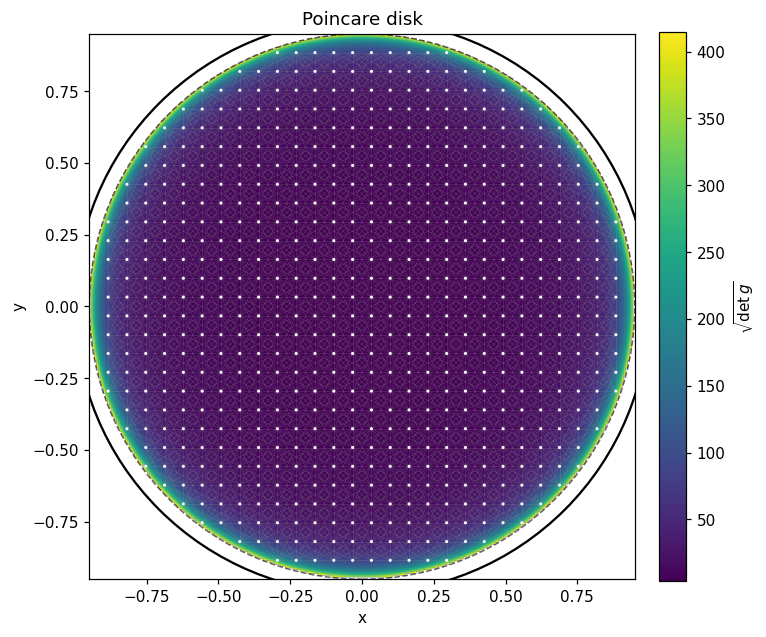

In [4]:
mani = PoincareDisk(rmax=0.95)
bounds = (-0.95, 0.95, -0.95, 0.95)
points, adj = build_graph(mani, bounds, 30, 30, [])
print(f"{len(points)} nodes,  {sum(len(a) for a in adj)//2} edges")
fig, ax = vz.visualize_query(mani, bounds, points, adj, title=r"Poincare disk", colorbar=True)
plt.show()


## Graph distance vs the exact geodesic


300 random pairs on a 7668-node Poincare graph
mean relative error vs exact geodesic: 0.00863229595094594
max  relative error: 0.026588117779203335


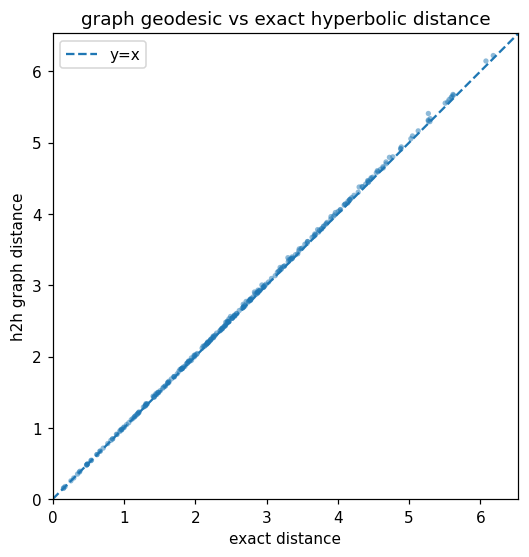

In [5]:
mani = PoincareDisk(rmax=0.95)
bounds = (-0.95, 0.95, -0.95, 0.95)
points, adj = build_graph(mani, bounds, 100, 100, [])
idx = H2HIndex(adj)
n = len(points)

g = np.random.default_rng(1)
d_exact, d_graph = [], []
while len(d_exact) < 300:
    s, t = int(g.integers(n)), int(g.integers(n))
    if s == t:
        continue
    d_exact.append(PoincareDisk.exact_dist(points[s], points[t]))
    d_graph.append(idx.query(s, t))
d_exact, d_graph = np.array(d_exact), np.array(d_graph)
rel = np.abs(d_graph - d_exact) / d_exact

print(f"{len(d_exact)} random pairs on a {n}-node Poincare graph")
print(f"mean relative error vs exact geodesic: {rel.mean()}")
print(f"max  relative error: {rel.max()}")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(d_exact, d_graph, s=12, alpha=0.5, edgecolors="none")
lim = [0, max(d_exact.max(), d_graph.max()) * 1.05]
ax.plot(lim, lim, "--", label="y=x")
ax.set_xlim(lim); 
ax.set_ylim(lim); 
ax.set_aspect("equal")
ax.set_xlabel("exact distance")
ax.set_ylabel("h2h graph distance")
ax.set_title("graph geodesic vs exact hyperbolic distance")
ax.legend()
plt.show()


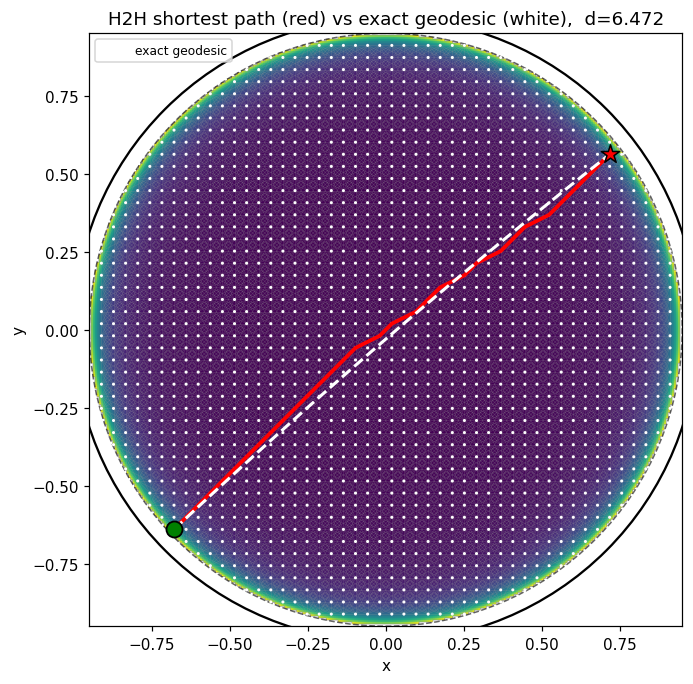

h2h graph distance: 6.472
exact hyperbolic: 6.4262


In [6]:
mani = PoincareDisk(rmax=0.95)
bounds = (-0.95, 0.95, -0.95, 0.95)
points, adj = build_graph(mani, bounds, 50, 50, [])
idx = H2HIndex(adj)

s = nearest_node(points, (-0.7, -0.65))
t = nearest_node(points, (0.7, 0.55))
dist, path = idx.query_path(s, t)

fig, ax = vz.visualize_query(mani, bounds, points, adj, path=path, title=f"H2H shortest path (red) vs exact geodesic (white),  d={dist:.3f}")
vz.plot_polyline(ax, mani.exact_geodesic(points[s], points[t], 120), color="white", ls="--", lw=2.0, label="exact geodesic")
ax.legend(loc="upper left", fontsize=8)
plt.show()
print("h2h graph distance:", round(dist, 4))
print("exact hyperbolic:", round(PoincareDisk.exact_dist(points[s], points[t]), 4))


## Shortest paths with obstacles


dist: 13.138858796349759


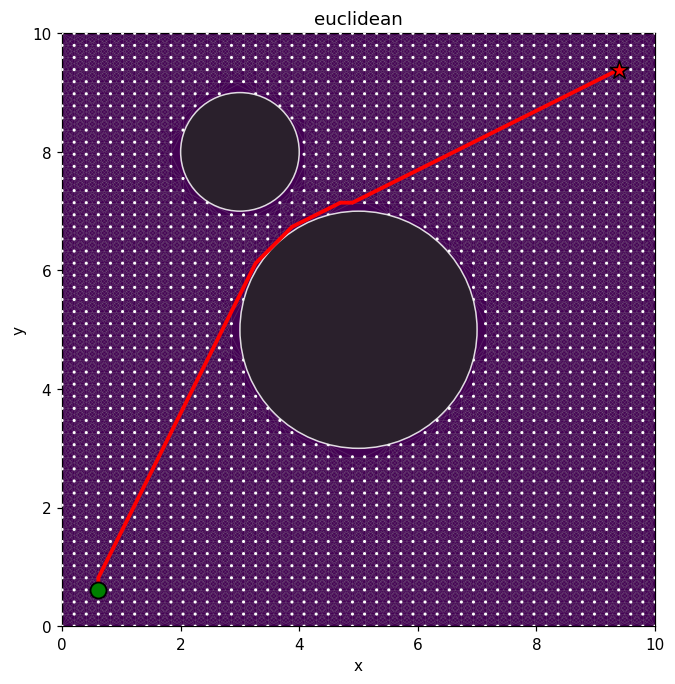

In [7]:
mani = Euclidean()
bounds = (0, 10, 0, 10)
obstacles = [Circle(5, 5, 2.0), Circle(3.0, 8.0, 1.0)]
points, adj = build_graph(mani, bounds, 50, 50, obstacles)
idx = H2HIndex(adj)

s = nearest_node(points, (0.7, 0.7)); t = nearest_node(points, (9.3, 9.3))
dist, path = idx.query_path(s, t)
fig, ax = vz.visualize_query(mani, bounds, points, adj, obstacles=obstacles, path=path, title=f"euclidean")
print("dist:", dist)
plt.show()


dist: 9.491277010195338


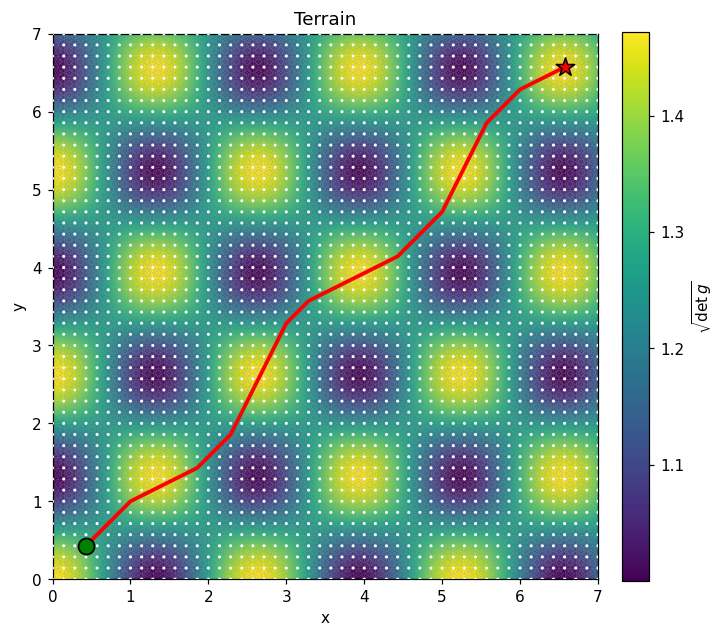

In [8]:
mani = Terrain(amp=0.9, freq=1.2)
bounds = (0, 7, 0, 7)
points, adj = build_graph(mani, bounds, 50, 50, [])
idx = H2HIndex(adj)

s = nearest_node(points, (0.4, 0.4)); t = nearest_node(points, (6.6, 6.6))
dist, path = idx.query_path(s, t)
fig, ax = vz.visualize_query(mani, bounds, points, adj, path=path, colorbar=True, title=f"Terrain")
print("dist:", dist)
plt.show()


## Statsitics


In [9]:
mani = Euclidean()
bounds = (0, 12, 0, 12)
obstacles = [Circle(6, 6, 2.0), Rectangle(1.5, 3.0, 7.0, 10.0)]
points, adj = build_graph(mani, bounds, 50, 50, obstacles)
n = len(points)
t0 = time.perf_counter()
idx = H2HIndex(adj)
build_ms = (time.perf_counter() - t0) * 1e3

print(f"nodes : {n}")
print(f"edges : {sum(len(a) for a in adj)//2}")
print(f"index build time : {build_ms} ms")
print(f"tree height h : {idx.h}")
print(f"treewidth w : {idx.width - 1}")
print(f"total label entries: {idx.label_entries}")
print(f"avg labels per vertex: {idx.label_entries / n}")


nodes : 2220
edges : 16483
index build time : 1477.3027498740703 ms
tree height h : 458
treewidth w : 139
total label entries: 604279
avg labels per vertex: 272.19774774774777


dijkstra: 3064.7839170414954 per query
h2h query: 9.542874991893768 per query
speed-up: 321.15939060764055x


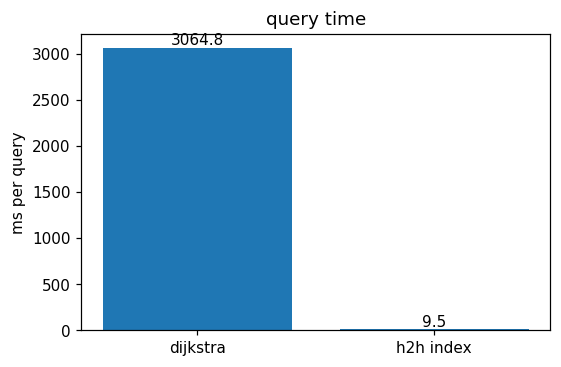

In [10]:
pairs = [(int(rng.integers(n)), int(rng.integers(n))) for _ in range(1000)]

t0 = time.perf_counter()
for s, t in pairs:
    dijkstra(adj, s, t)
dij_us = (time.perf_counter() - t0) / len(pairs) * 1e6

t0 = time.perf_counter()
for s, t in pairs:
    idx.query(s, t)
h2h_us = (time.perf_counter() - t0) / len(pairs) * 1e6

print(f"dijkstra: {dij_us} per query")
print(f"h2h query: {h2h_us} per query")
print(f"speed-up: {dij_us / h2h_us}x")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.bar(["dijkstra", "h2h index"], [dij_us, h2h_us])
ax.set_ylabel("ms per query")
ax.set_title(f"query time")
for i, v in enumerate([dij_us, h2h_us]):
    ax.text(i, v, f"{v:.1f}", ha="center", va="bottom")
plt.show()


## Multiple connected components

Generally H2H indexing applied on a graph with one connected component, but an obsticle can split the graph into multiple connected components. So we solve this:

1. label every vertex with its connected component (bfs)
2. nuild an independent h2h index per component
3. A query first checks whether $s$ and $t$ share a component: 1) if different components then distance is inf and no path; 2) else if same component then we do query on this component


2 connected components, sizes = [1620, 1620]


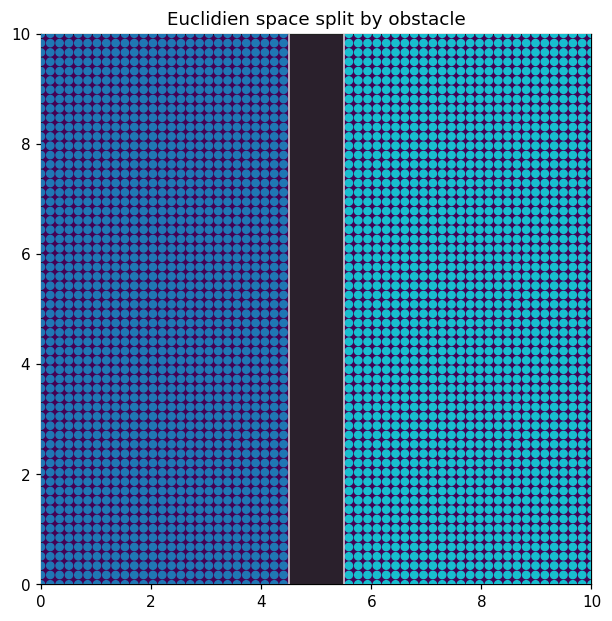

In [11]:
mani = Euclidean()
bounds = (0, 10, 0, 10)
wall = [Rectangle(4.5, 5.5, -1.0, 11.0)]
points, adj = build_graph(mani, bounds, 60, 60, wall)
comp, members = connected_comps(adj)
mindex = MultiH2HIndex(adj)
print(f"{len(members)} connected components, sizes = {sorted(len(m) for m in members)}")

fig, ax = plt.subplots(figsize=(6.5, 6.5))
vz.plot_background(ax, mani, bounds, res=180)
vz.plot_obstacles(ax, wall)
sc = vz.plot_components(ax, points, comp, node_size=22)
ax.set_xlim(bounds[0], bounds[1]); ax.set_ylim(bounds[2], bounds[3]); ax.set_aspect("equal")
ax.set_title("Euclidien space split by obstacle")
plt.show()


same component: False
(1.0, 1.0) to (3.5, 9.0): d=8.566274519067258
(6.5, 1.0) to (9.0, 9.0): d=8.566274519067258


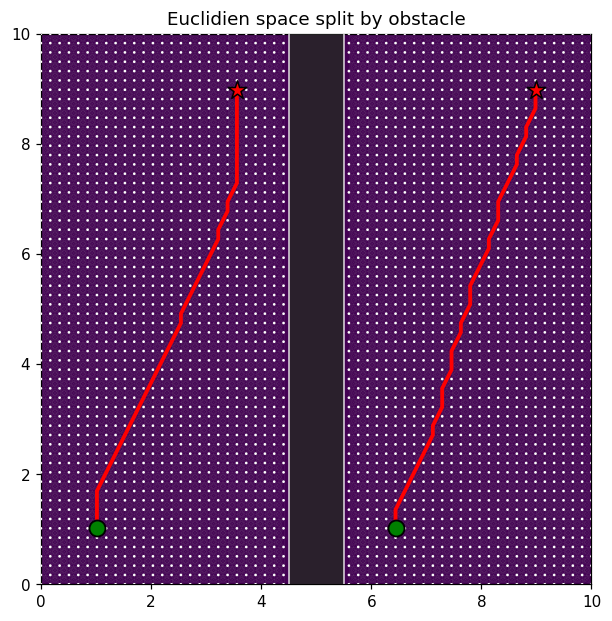

In [12]:
s_left  = nearest_node(points, (1.5, 5.0))
t_right = nearest_node(points, (8.5, 5.0))
print("same component:", mindex.same_component(s_left, t_right))

fig, ax = plt.subplots(figsize=(6.5, 6.5))
vz.plot_background(ax, mani, bounds, res=180)
vz.plot_obstacles(ax, wall)
vz.plot_graph(ax, points, adj, node_size=3, edge_alpha=0.12)

for (a, b) in [(((1.0, 1.0), (3.5, 9.0))), (((6.5, 1.0), (9.0, 9.0)))]:
    s = nearest_node(points, a); t = nearest_node(points, b)
    d, path = mindex.query_path(s, t)
    vz.plot_path(ax, points, path)
    print(f"{a} to {b}: d={d}")

ax.set_xlim(bounds[0], bounds[1]); ax.set_ylim(bounds[2], bounds[3]); ax.set_aspect("equal")
ax.set_title("Euclidien space split by obstacle")
plt.show()


## Adaptive sampling

Instead of sampling uniformly, choose sampling density $\rho(x)$

$$\rho(x)\ \propto\ w_g\,\lVert\nabla g(x)\rVert \;+\; w_k\,\lvert K(x)\rvert \;+\; w_o\,e^{-\,d_g(x,\partial O)/\sigma},$$

more samples where the metric changes fast, where the curvature is high, and
near obstacle boundaries. $V_{ad}=V_{int}\cup V_{\partial O}$:

766 nodes


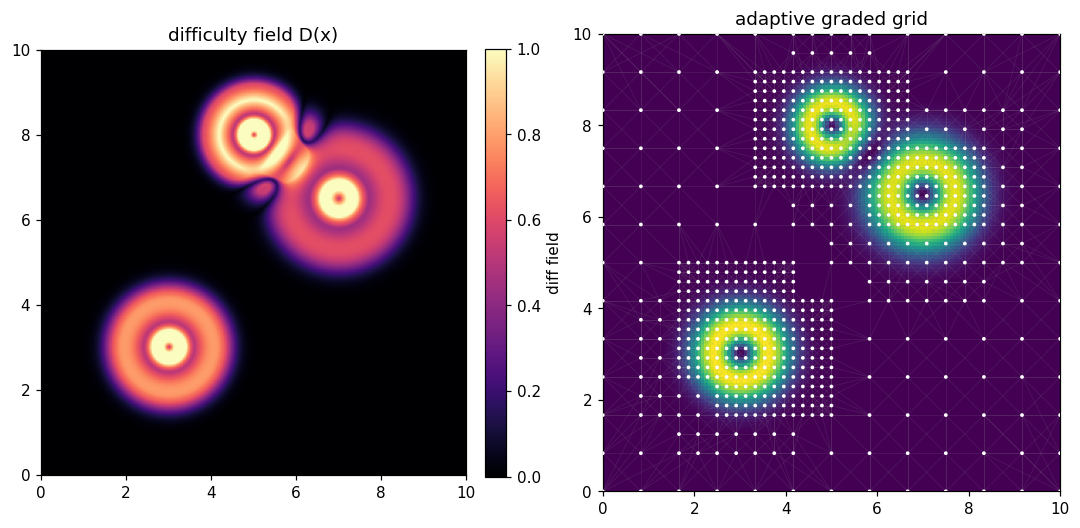

In [13]:
from rgeo.graphs import sampling as ad
from rgeo.manifolds import GaussianHills

hills = [(3.0, 3.0, 2.2, 0.6), (7.0, 6.5, 2.5, 0.7), (5.0, 8.0, 1.8, 0.5)]
mani = GaussianHills(hills)
bounds = (0, 10, 0, 10)

xs, ys, D = ad.difficulty_field(mani, bounds, [], res=300)
pts_ad, adj_ad = ad.build_adaptive_graph(mani, bounds, [], n0=12, max_levels=2, tau=0.33, k=8, field=(xs, ys, D))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
vz.plot_field(axes[0], xs, ys, D, manifold=mani, colorbar=True)
axes[0].set_title(r"difficulty field D(x)")
vz.plot_background(axes[1], mani, bounds, res=140)
vz.plot_graph(axes[1], pts_ad, adj_ad, node_size=6, edge_alpha=0.15)
axes[1].set_title(f"adaptive graded grid")
print(f"{len(pts_ad)} nodes")
for a in axes:
    a.set_xlim(0, 10); a.set_ylim(0, 10); a.set_aspect("equal")
plt.show()


uniform (488 nodes):  mean 6.04%  p95 10.85%  max 27.50%
uniform + V_dO (570 nodes):  mean 4.57%  p95 8.48%  max 12.62%


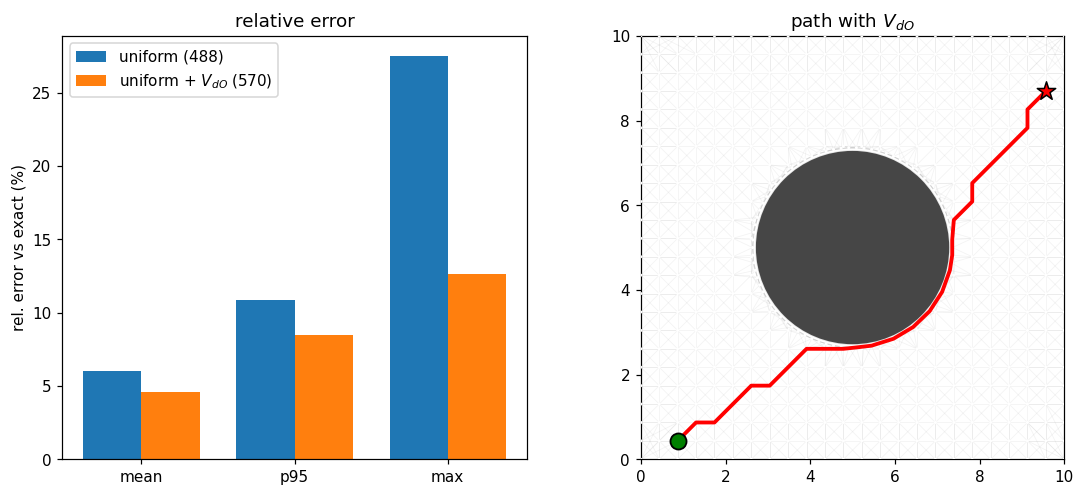

In [14]:
mani = Euclidean()
bounds = (0, 10, 0, 10)
c, r = (5.0, 5.0), 2.3
obs = [Circle(c[0], c[1], r)]


def exact_around_disk(s, t, c, r):
    s = np.asarray(s, float); t = np.asarray(t, float); c = np.asarray(c, float)
    d = t - s; f = s - c
    a = d @ d; b = 2 * f @ d
    cc = f @ f - r * r
    disc = b * b - 4 * a * cc
    hit = False
    if disc > 0:
        sq = np.sqrt(disc); t1 = (-b - sq) / (2 * a); t2 = (-b + sq) / (2 * a)
        hit = (0 < t1 < 1) or (0 < t2 < 1)
    if not hit:
        return np.linalg.norm(t - s)
    ds = np.linalg.norm(s - c); dt = np.linalg.norm(t - c)
    ls = np.sqrt(max(ds * ds - r * r, 0)); lt = np.sqrt(max(dt * dt - r * r, 0))
    ang = np.arccos(np.clip((s - c) @ (t - c) / (ds * dt), -1, 1))
    arc = max(ang - np.arccos(np.clip(r / ds, -1, 1)) - np.arccos(np.clip(r / dt, -1, 1)), 0.0)
    return ls + lt + r * arc


rng = np.random.default_rng(11)
L = 60
landmarks = []
while len(landmarks) < L:
    p = rng.uniform([0.3, 0.3], [9.7, 9.7])
    if not obs[0].blocked(p):
        landmarks.append(p)
landmarks = np.array(landmarks)
pairs = [(i, j) for i in range(L) for j in range(i + 1, L)]
d_ex = {(i, j): exact_around_disk(landmarks[i], landmarks[j], c, r) for i, j in pairs}
wrap = [(i, j) for i, j in pairs if d_ex[(i, j)] > np.linalg.norm(landmarks[i] - landmarks[j]) + 1e-9]
Vb = ad.samlpe_boundary_points(mani, obs, bounds, offset=0.06, spacing=0.18)


def wrap_err(points, adj):
    midx = MultiH2HIndex(adj)
    lm = [nearest_node(points, p) for p in landmarks]
    e = [abs(midx.query(lm[i], lm[j]) - d_ex[(i, j)]) / d_ex[(i, j)]
         for (i, j) in wrap if midx.same_component(lm[i], lm[j])]
    e = np.array(e)
    return e.mean(), np.percentile(e, 95), e.max()


pu, au = ad.build_uniform_graph(mani, bounds, 24, 24, obs, k=8)
pv, av = ad.graph_from_points(mani, list(pu) + list(Vb), obs, k=8)
eu, ev = wrap_err(pu, au), wrap_err(pv, av)
print(f"uniform ({len(pu)} nodes):  mean {eu[0]:.2%}  p95 {eu[1]:.2%}  max {eu[2]:.2%}")
print(f"uniform + V_dO ({len(pv)} nodes):  mean {ev[0]:.2%}  p95 {ev[1]:.2%}  max {ev[2]:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = np.arange(3); w = 0.38
axes[0].bar(x - w / 2, [v * 100 for v in eu], w, label=f"uniform ({len(pu)})")
axes[0].bar(x + w / 2, [v * 100 for v in ev], w, label=f"uniform + $V_{{dO}}$ ({len(pv)})")
axes[0].set_xticks(x); axes[0].set_xticklabels(["mean", "p95", "max"])
axes[0].set_ylabel("rel. error vs exact (%)")
axes[0].set_title("relative error")
axes[0].legend()
vz.plot_obstacles(axes[1], obs)
vz.plot_graph(axes[1], pv, av, node_size=4, edge_alpha=0.12)
lm = [nearest_node(pv, p) for p in landmarks]
i, j = max(wrap, key=lambda ij: d_ex[ij])
_, path = MultiH2HIndex(av).query_path(lm[i], lm[j])
vz.plot_path(axes[1], pv, path)
axes[1].set_xlim(0, 10)
axes[1].set_ylim(0, 10)
axes[1].set_aspect("equal")
axes[1].set_title(r"path with $V_{dO}$")
plt.show()


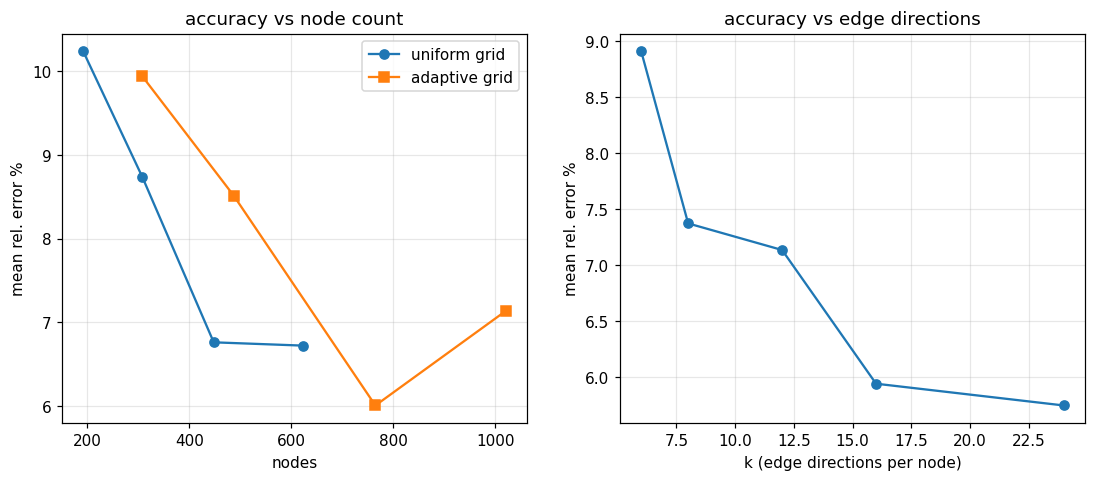

In [15]:
mani = PoincareDisk(rmax=0.94)
bounds = (-0.9, 0.9, -0.9, 0.9)
rng = np.random.default_rng(2)
L = 50
lm = []
while len(lm) < L:
    p = rng.uniform(-0.85, 0.85, 2)
    if mani.in_domain(p):
        lm.append(p)
lm = np.array(lm)
pairs = [(i, j) for i in range(L) for j in range(i + 1, L)]
d_ex = np.array([PoincareDisk.exact_dist(lm[i], lm[j]) for i, j in pairs])


def mean_err(points, adj):
    midx = MultiH2HIndex(adj)
    ids = [nearest_node(points, p) for p in lm]
    return np.mean([abs(midx.query(ids[i], ids[j]) - d_ex[t]) / d_ex[t]
                    for t, (i, j) in enumerate(pairs) if midx.same_component(ids[i], ids[j])])


fieldP = ad.difficulty_field(mani, bounds, [], res=80, weights=(1.0, 0.0, 0.0))
uni, ada = [], []
for R in (16, 20, 24, 28):
    p, a = ad.build_uniform_graph(mani, bounds, R, R, [], k=8)
    uni.append((len(p), mean_err(p, a)))
for n0 in (14, 18, 22, 26):
    p, a = ad.build_adaptive_graph(mani, bounds, [], n0=n0, max_levels=1, tau=0.33, k=8, field=fieldP)
    ada.append((len(p), mean_err(p, a)))
ks = [6, 8, 12, 16, 24]

kerr = []
for k in ks:
    p, a = ad.build_uniform_graph(mani, bounds, 26, 26, [], k=k)
    kerr.append(mean_err(p, a))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot([u[0] for u in uni], [u[1] * 100 for u in uni], "o-", label="uniform grid")
axes[0].plot([u[0] for u in ada], [u[1] * 100 for u in ada], "s-", label="adaptive grid")
axes[0].set_xlabel("nodes")
axes[0].set_ylabel("mean rel. error %")
axes[0].set_title("accuracy vs node count")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ks, [e * 100 for e in kerr], "o-")
axes[1].set_xlabel("k (edge directions per node)")
axes[1].set_ylabel("mean rel. error %")
axes[1].set_title("accuracy vs edge directions")
axes[1].grid(alpha=0.3)
plt.show()


More nodes do not nessarely help, more edges often has more impact

## Manifold decomposition

1976 nodes, 367 separators, 16 portals each


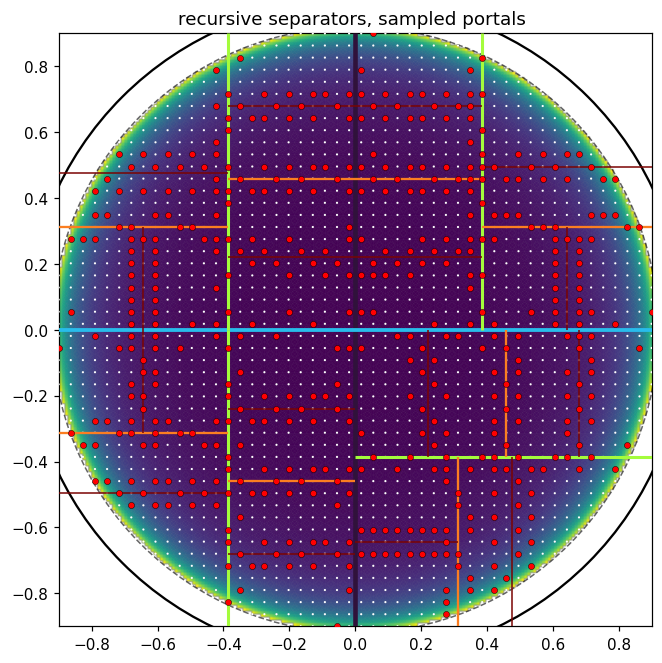

In [16]:
from rgeo.oracles import SeparatorIndex

mani = PoincareDisk(rmax=0.92)
bounds = (-0.9, 0.9, -0.9, 0.9)
points, adj = build_graph(mani, bounds, 50, 50, [])
h2h = H2HIndex(adj)
sepix = SeparatorIndex(points, adj, k=16, leaf_size=8)

print(f"{len(points)} nodes, {sepix.num_seps} separators, {sepix.max_portals} portals each")
fig, ax = plt.subplots(figsize=(7, 7))
vz.plot_background(ax, mani, bounds, res=200)
vz.plot_graph(ax, points, adj, node_size=2, edge_alpha=0.06)
vz.plot_separators(ax, sepix, max_depth=4)
ax.set_xlim(bounds[0], bounds[1]); ax.set_ylim(bounds[2], bounds[3]); ax.set_aspect("equal")
ax.set_title("recursive separators, sampled portals ")
plt.show()


separator d = 5.986356430068398
exact d = 5.986043506386716
rel error = 5.2275544163283305e-05


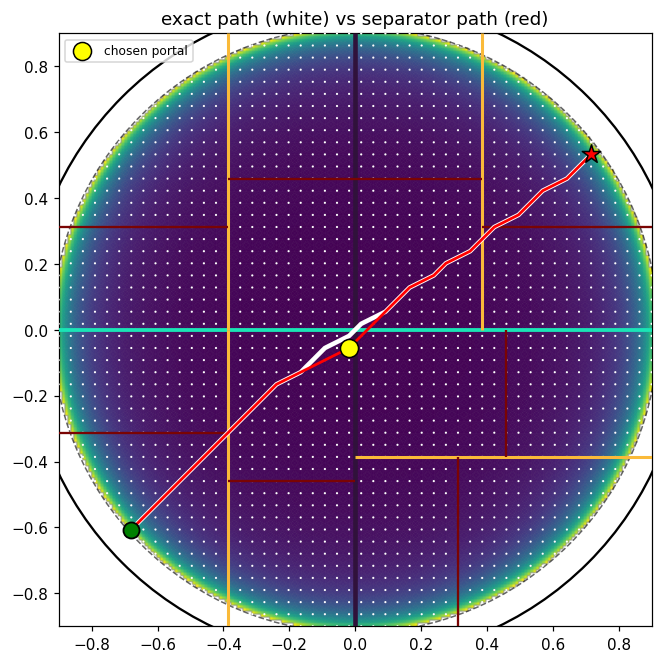

In [17]:
s = nearest_node(points, (-0.7, -0.6))
t = nearest_node(points, (0.7, 0.55))
d_sep, path_sep = sepix.query_path(s, t)
d_exact, path_exact = h2h.query_path(s, t)
sep = sepix.lcs(s, t)
tot = sepix.label[s][sep] + sepix.label[t][sep]
p = int(sepix.sep_portals[sep][int(tot.argmin())])
print(f"separator d = {d_sep}")
print(f"exact d = {d_exact}")
print(f"rel error = {(d_sep - d_exact) / d_exact}")

fig, ax = plt.subplots(figsize=(7, 7))
vz.plot_background(ax, mani, bounds, res=200)
vz.plot_graph(ax, points, adj, node_size=2, edge_alpha=0.05)
vz.plot_separators(ax, sepix, max_depth=3, show_portals=False)
vz.plot_path(ax, points, path_exact, color="white", lw=3.0, marker_ends=False)
vz.plot_path(ax, points, path_sep, color="red", lw=1.8)
ax.scatter([points[p][0]], [points[p][1]], s=140, c="yellow", edgecolors="black", zorder=8, label="chosen portal")
ax.set_xlim(bounds[0], bounds[1]); ax.set_ylim(bounds[2], bounds[3]); ax.set_aspect("equal")
ax.set_title("exact path (white) vs separator path (red)")
ax.legend(loc="upper left", fontsize=8)
plt.show()


### Accuracy ($\uparrow k$) and $O(k)$ query speed


k=4: mean 7.422638856471386, median 2.2293758379208066, p90 16.957841075457566
k=8: mean 1.8594095822801955, median 0.38648160029616774, p90 3.549584061131558
k=16: mean 0.5488345190889398, median 0.02511244863549076, p90 1.2281369508746915
k=32: mean 0.14416571044920595, median 0.0, p90 0.29418731847017887
k=64: mean 0.03706247636570568, median 0.0, p90 0.028348183352278872
query time: dijkstra 2931.5191040514037ms, h2h 6.182208540849388 ms, separator 2.158833551220596 ms


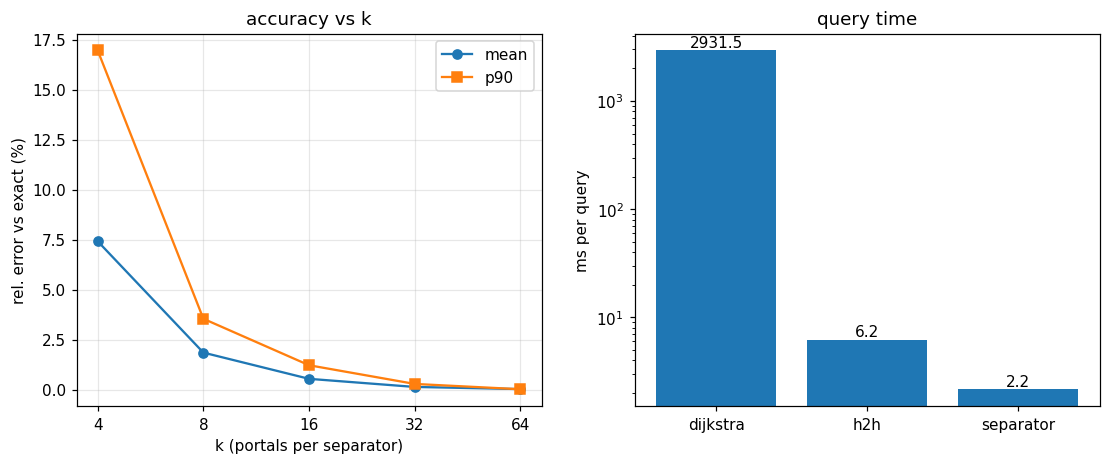

In [18]:
import time

rng = np.random.default_rng(3)
n = len(points)
qp = [(int(rng.integers(n)), int(rng.integers(n))) for _ in range(2000)]
ks = [4, 8, 16, 32, 64]
means, p90s = [], []
for k in ks:
    ix = SeparatorIndex(points, adj, k=k, leaf_size=8)
    e = [(ix.query(s, t) - h2h.query(s, t)) / h2h.query(s, t)
         for s, t in qp if s != t and h2h.query(s, t) > 0]
    e = np.array(e) * 100
    means.append(e.mean()); p90s.append(np.percentile(e, 90))
    print(f"k={k}: mean {e.mean()}, median {np.median(e)}, p90 {np.percentile(e,90)}")

ix = SeparatorIndex(points, adj, k=16, leaf_size=8)
def qtime(fn):
    t0 = time.perf_counter()
    for s, t in qp:
        fn(s, t)
    return (time.perf_counter() - t0) / len(qp) * 1e6
t_sep = qtime(ix.query); 
t_h2h = qtime(h2h.query); 
t_dij = qtime(lambda s, t: dijkstra(adj, s, t))
print(f"query time: dijkstra {t_dij}ms, h2h {t_h2h} ms, separator {t_sep} ms")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(ks, means, "o-", label="mean")
axes[0].plot(ks, p90s, "s-", label="p90")
axes[0].set_xscale("log", base=2); axes[0].set_xticks(ks); axes[0].set_xticklabels(ks)
axes[0].set_xlabel("k (portals per separator)")
axes[0].set_ylabel("rel. error vs exact (%)")
axes[0].set_title("accuracy vs k")
axes[0].legend(); 
axes[0].grid(alpha=0.3)
axes[1].bar(["dijkstra", "h2h", "separator"], [t_dij, t_h2h, t_sep])
axes[1].set_ylabel("ms per query"); axes[1].set_yscale("log")
axes[1].set_title("query time")

for i, v in enumerate([t_dij, t_h2h, t_sep]):
    axes[1].text(i, v, f"{v:.1f}", ha="center", va="bottom")
plt.show()
